In [ ]:
%pip -q install pyuvdata
!nvidia-smi

Tue Nov  3 22:44:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# -*- coding: utf-8 -*-
"""Copy of MG_CS163.ipynb

Automatically generated by Colab.

Original file is located at
    https://colab.research.google.com/drive/1QDAPe7p_qtFDpFkRrkCbu5tz2ul-hr0E
"""

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import copy, glob, random
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pyuvdata import UVData

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

TENSORS = '/content/drive/MyDrive/cs163_tensors'
RAW_DIR = str(next((p for p in (
    Path('/content/drive/MyDrive/CS 163/cs163_data'),
    Path('/content/drive/MyDrive/2026-27 School Year/FA 26/Cs 163/cs163_data')
) if p.exists()), Path('/content/drive/MyDrive/CS 163/cs163_data')))
OUT_DIR = Path('/content/drive/MyDrive/cs163_loss_comparison_v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

K = 214
HIDDEN = 256
LR = 1e-3
EPOCHS = 200
BS = 32
IMG_PIX, IMG_FOV = 32, 0.5

# Fast primary experiment; image-heavy baselines are optional below.
RUN_LOSSES = ['gain_mse', 'pair_mse', 'pair_huber', 'gain_plus_pair', 'gain_plus_vis']
# Optional: append 'original_product', 'gain_plus_image' to compare image-heavy losses.
SELECT_METRIC = 'gain'   # fixed checkpoint rule across objectives
CORRECTION_MODE = 'multiply'  # measured CALFITS correction-gain convention
EVAL_IMAGE_EVERY = 20         # DFT diagnostic every N epochs, not every batch
RESUME_EVERY = 5              # persistent optimizer checkpoint interval
# Relative-vis errors are normalized separately per sample; gain/pair use reference gain units.

print('device:', device, '| run:', RUN_LOSSES)

def load_k(k):
    x = np.load(f'{TENSORS}/X.npy', mmap_mode='r')
    y = np.load(f'{TENSORS}/Y.npy', mmap_mode='r')
    m = np.load(f'{TENSORS}/M.npy', mmap_mode='r')
    assert x.shape[-2:] == (214, 214) and 1 <= k <= 214
    return (torch.from_numpy(np.array(x[:, :, :k, :k], dtype=np.float32, copy=True)),
            torch.from_numpy(np.array(y[:, :, :k], dtype=np.float32, copy=True)),
            torch.from_numpy(np.array(m[:, :k], copy=True)))

def make_tvt(n, seed=0):
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed))
    n_tr, n_va = int(0.8 * n), int(0.1 * n)
    return {'train': perm[:n_tr], 'val': perm[n_tr:n_tr+n_va], 'test': perm[n_tr+n_va:]}

def batches(split, bs=BS, *, shuffle=False, epoch=0):
    idx = splits[split]
    if shuffle:
        order = torch.randperm(len(idx), generator=torch.Generator().manual_seed(SEED + 10000 + epoch))
        idx = idx[order]
    for start in range(0, len(idx), bs):
        b = idx[start:start+bs]
        yield (X[b].to(device, non_blocking=True),
               Y[b].to(device, non_blocking=True),
               M[b].to(device, non_blocking=True))

X, Y, M = load_k(K)
splits = make_tvt(len(X), SEED)
print('X', tuple(X.shape), '| Y', tuple(Y.shape), '| M', tuple(M.shape))
print({k: len(v) for k,v in splits.items()})

class AntennaMLP(nn.Module):
    """shared MLP over each row and col"""
    def __init__(self, n, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4 * n, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x):                          # (B, 2, K, K)
        b, _, n, _ = x.shape
        row = x.permute(0, 2, 1, 3).reshape(b, n, 2 * n)
        col = x.permute(0, 3, 1, 2).reshape(b, n, 2 * n)
        g = self.net(torch.cat([row, col], -1))
        return torch.cat([g[..., 0], g[..., 1]], 1)  # (B, 2K)

def mlp_input(x):
    return x / (x.flatten(1).std(1).view(-1, 1, 1, 1) + 1e-6)

def to_c(t):
    return torch.complex(t[:, 0], t[:, 1]) if t.dim() == 3 else torch.complex(t[:, :K], t[:, K:])

print('AntennaMLP params:', sum(p.numel() for p in AntennaMLP(K).parameters()))

def build_dft():
    files = sorted(glob.glob(f'{RAW_DIR}/uncalib_data_*.uvfits'))
    if not files:
        raise FileNotFoundError(f'No UVFITS in {RAW_DIR}; update RAW_DIR to match Drive')
    uv = UVData(); uv.read(files[0], run_check=False)
    ants = np.union1d(uv.ant_1_array, uv.ant_2_array)
    i = np.searchsorted(ants, uv.ant_1_array)
    j = np.searchsorted(ants, uv.ant_2_array)
    good = i != j
    i, j = i[good], j[good]
    lam = 299792458.0 / float(uv.freq_array.ravel()[0])
    u, v = (uv.uvw_array[good, :2] / lam).T
    grid = np.linspace(-IMG_FOV, IMG_FOV, IMG_PIX)
    l, m = np.meshgrid(grid, grid)
    phase = 2j*np.pi*(np.outer(l.ravel(), u) + np.outer(m.ravel(), v))
    A_full = torch.from_numpy(np.exp(phase).astype(np.complex64)).to(device)
    valid = (i < K) & (j < K)
    return (A_full[:, valid],
            torch.from_numpy(i[valid]).to(device),
            torch.from_numpy(j[valid]).to(device))

A, bi, bj = build_dft()
print('DFT', tuple(A.shape), '| cross-correlations:', len(bi))
def stage_tensors_on_gpu():
    global X, Y, M
    if device != 'cuda':
        return
    free, total = torch.cuda.mem_get_info()
    required = sum(t.numel() * t.element_size() for t in (X, Y, M))
    if required < 0.55 * free:
        X, Y, M = X.to(device), Y.to(device), M.to(device)
        print(f'Cached all dataset tensors on GPU ({required/2**30:.2f} GiB)')
    else:
        print(f'Keeping dataset on CPU ({required/2**30:.2f} GiB; GPU free {free/2**30:.2f} GiB)')

stage_tensors_on_gpu()


def gain_products(g):
    """Unique measured cross-correlations, in antenna-pair ordering from UVFITS."""
    return g[:, bi] * g[:, bj].conj()


def calibrated_visibilities(V, g):
    """V has shape (B,K,K). Gain convention was determined experimentally."""
    p = gain_products(g)
    vb = V[:, bi, bj]
    if CORRECTION_MODE == 'multiply':
        return vb * p
    if CORRECTION_MODE == 'divide':
        safe = torch.where(p.abs() < 1e-3, 1e-3 * torch.ones_like(p), p)
        return vb / safe
    raise ValueError('CORRECTION_MODE must be multiply or divide')


def calibrate(V, g):
    return calibrated_visibilities(V, g)


def make_image(Vb):
    return (Vb @ A.T).real.reshape(-1, IMG_PIX, IMG_PIX) / A.shape[1]


def gain_loss(pred, y, m):
    """Global phase-aligned complex squared error (unchanged supervised baseline)."""
    gp, gt, w = to_c(pred), to_c(y), m.float()
    ph = torch.angle((gp * gt.conj() * w).sum(1, keepdim=True)).detach()
    return ((gp * torch.exp(-1j * ph) - gt).abs().square() * w).sum() / w.sum().clamp_min(1)


def pair_data(pred, y, m):
    """Only i<j recorded cross-correlations, never autocorrelations/diagonal."""
    gp, gt = to_c(pred), to_c(y)
    residual = gain_products(gp) - gain_products(gt)
    good = m[:, bi].bool() & m[:, bj].bool()
    return residual, good


def valid_mean_per_sample(values, good):
    counts = good.sum(1)
    per_sample = (values * good.float()).sum(1) / counts.clamp_min(1)
    return per_sample[counts > 0].mean() if bool((counts > 0).any()) else values.sum() * 0


def pair_loss(pred, y, m):
    r, good = pair_data(pred, y, m)
    return valid_mean_per_sample(r.abs().square(), good)


def pair_huber_loss(pred, y, m):
    """Radial Huber penalty: quadratic inliers, bounded residual influence."""
    if HUBER_DELTA is None:
        raise RuntimeError('Train/load gain_mse first to calibrate HUBER_DELTA')
    r, good = pair_data(pred, y, m)
    r2 = r.abs().square()
    radius = (r2 + 1e-12).sqrt()
    delta = HUBER_DELTA
    penalty = torch.where(radius <= delta, 0.5 * r2, delta * (radius - 0.5 * delta))
    return valid_mean_per_sample(penalty, good)


def corrected_visibility_loss(pred, x, y, m):
    """Per-sample relative MSE of corrected visibilities, without any DFT."""
    V = torch.complex(x[:, 0], x[:, 1])
    gp, gt = to_c(pred), to_c(y)
    vp = calibrated_visibilities(V, gp)
    vt = calibrated_visibilities(V, gt)
    valid = m[:, bi].bool() & m[:, bj].bool()
    numerator = ((vp - vt).abs().square() * valid).sum(1)
    denominator = (vt.abs().square() * valid).sum(1).clamp_min(1e-12)
    ratio = numerator / denominator
    return ratio[valid.any(1)].mean() if bool(valid.any()) else numerator.sum() * 0


def image_loss(pred, x, y, m):
    """Existing dirty-image diagnostic with empirically established gain direction."""
    V = torch.complex(x[:, 0], x[:, 1])
    ok = (m[:, bi] & m[:, bj]).float()
    img_pred = make_image(calibrated_visibilities(V, to_c(pred)) * ok)
    with torch.no_grad():
        ref = make_image(calibrated_visibilities(V, to_c(y)) * ok)
    scale = ref.abs().mean() + 1e-8
    return (((img_pred-ref)/scale)**2).mean()


def huber_gain_loss(pred, y, m, delta=0.25):
    """Legacy gain Huber for optional comparison; threshold is not data calibrated."""
    gp, gt, w = to_c(pred), to_c(y), m.float()
    ph = torch.angle((gp * gt.conj() * w).sum(1, keepdim=True)).detach()
    residual = (gp * torch.exp(-1j * ph) - gt).abs()
    loss = torch.where(residual < delta, 0.5*residual.square(), delta*(residual-0.5*delta))
    return (loss*w).sum()/w.sum().clamp_min(1)

LOSS_NAMES = ('gain_mse', 'pair_mse', 'pair_huber', 'gain_plus_pair',
              'gain_plus_vis', 'original_product', 'gain_plus_image', 'huber_gain')
SCALES = None
HUBER_DELTA = None


def objective(name, pred, x, y, m, *, cache=None):
    cache = {} if cache is None else cache
    def get(key):
        if key not in cache:
            funcs = {'gain': lambda: gain_loss(pred, y, m),
                     'pair': lambda: pair_loss(pred, y, m),
                     'vis': lambda: corrected_visibility_loss(pred, x, y, m),
                     'image': lambda: image_loss(pred, x, y, m),
                     'pair_huber': lambda: pair_huber_loss(pred, y, m),
                     'huber': lambda: huber_gain_loss(pred, y, m)}
            cache[key] = funcs[key]()
        return cache[key]
    if name == 'gain_mse': return get('gain')
    if name == 'pair_mse': return get('pair')
    if name == 'pair_huber': return get('pair_huber')
    if name == 'gain_plus_pair':
        return get('gain')/SCALES['gain'] + get('pair')/SCALES['pair']
    if name == 'gain_plus_vis':
        return get('gain')/SCALES['gain'] + get('vis')/SCALES['vis']
    if name == 'original_product': return get('gain') * get('image')
    if name == 'gain_plus_image':
        return get('gain')/SCALES['gain'] + get('image')/SCALES['image']
    if name == 'huber_gain': return get('huber')
    raise ValueError(f'Unknown loss {name}; options: {LOSS_NAMES}')

assert set(RUN_LOSSES).issubset(LOSS_NAMES) and len(RUN_LOSSES) == len(set(RUN_LOSSES))
assert CORRECTION_MODE in ('multiply', 'divide')

import json, math, time, os

@torch.no_grad()
def evaluate(model, split, image_diagnostic=False):
    model.eval()
    keys = ['gain', 'pair', 'vis'] + (['image'] if image_diagnostic else [])
    totals = {key: 0.0 for key in keys}
    n = 0
    for x, y, m in batches(split):
        pred = model(mlp_input(x))
        vals = {'gain': gain_loss(pred, y, m),
                'pair': pair_loss(pred, y, m),
                'vis': corrected_visibility_loss(pred, x, y, m)}
        if image_diagnostic:
            vals['image'] = image_loss(pred, x, y, m)
        for key, val in vals.items():
            totals[key] += val.item() * len(x)
        n += len(x)
    result = {key: val / n for key, val in totals.items()}
    if not image_diagnostic:
        result['image'] = float('nan')
    result['objective'] = float('nan') # training objectives are not comparable
    return result


def initial_scales(initial_weights):
    """Dimensionless normalization from TRAIN data, with identical model initialization."""
    model = AntennaMLP(K).to(device)
    model.load_state_dict(initial_weights)
    model.eval()
    acc = {'gain': [], 'pair': [], 'vis': [], 'image': []}
    with torch.no_grad():
        for batch_no, (x, y, m) in enumerate(batches('train')):
            if batch_no >= 4: break
            p = model(mlp_input(x))
            acc['gain'].append(gain_loss(p, y, m).item())
            acc['pair'].append(pair_loss(p, y, m).item())
            acc['vis'].append(corrected_visibility_loss(p, x, y, m).item())
            # Only needed for optional expensive image-based losses.
            if any(name in RUN_LOSSES for name in ('gain_plus_image',)):
                acc['image'].append(image_loss(p, x, y, m).item())
    result = {key: max(float(np.mean(val)), 1e-10) for key, val in acc.items() if val}
    print('Initial training-only scales:', result)
    return result


@torch.no_grad()
def calibrate_pair_huber_delta(baseline_model):
    """Train-only radial-median Rayleigh estimate, 95% inlier radius.

    If Re/Im baseline residuals are iid N(0, sigma^2), |r| is Rayleigh.
    median(|r|) = sigma*sqrt(2 ln 2); q95 = sigma*sqrt(2 ln 20).
    Thus q95 = median(|r|)*sqrt(ln 20 / ln 2).
    """
    baseline_model.eval()
    sampled = []
    for idx, (x, y, m) in enumerate(batches('train')):
        if idx >= 8: break
        pred = baseline_model(mlp_input(x))
        r, valid = pair_data(pred, y, m)
        values = r.abs()[valid]
        if values.numel():
            stride = max(1, values.numel() // 16000)
            sampled.append(values[::stride].detach().cpu())
    if not sampled:
        raise RuntimeError('No valid pair residuals: cannot calibrate Huber delta')
    median = torch.cat(sampled).median().item()
    delta = max(1e-6, median * math.sqrt(math.log(20) / math.log(2)))
    print(f'Pair-Huber delta (Rayleigh 95th-percentile rule; train only): {delta:.6g}')
    return delta


def dump_atomic(obj, path):
    temp = str(path) + '.tmp'
    torch.save(obj, temp)
    os.replace(temp, path)


def train_one(name, initial_weights):
    model = AntennaMLP(K).to(device)
    model.load_state_dict(initial_weights)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    history = {'train': [], 'val': []}
    best, best_epoch, start_epoch = float('inf'), -1, 0
    best_path = OUT_DIR / f'mlp_k{K}_{name}.pt'
    last_path = OUT_DIR / f'mlp_k{K}_{name}_last.pt'
    done_path = OUT_DIR / f'mlp_k{K}_{name}_done.json'

    if done_path.exists() and best_path.exists():
        record = json.loads(done_path.read_text())
        print(f'{name}: already complete; loading persisted results')
        model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
        return model, record['history'], record['test'], record['best_epoch']

    if last_path.exists():
        st = torch.load(last_path, map_location=device, weights_only=True)
        if st.get('epochs_total') != EPOCHS:
            raise RuntimeError(f'{name}: checkpoint EPOCHS mismatch; use another OUT_DIR')
        model.load_state_dict(st['model'])
        opt.load_state_dict(st['optimizer'])
        history, best, best_epoch = st['history'], st['best'], st['best_epoch']
        start_epoch = st['epoch'] + 1
        print(f'{name}: resuming epoch {start_epoch+1}/{EPOCHS}')

    for epoch in range(start_epoch, EPOCHS):
        model.train()
        totals = {'gain': 0.0, 'pair': 0.0, 'vis': 0.0, 'objective': 0.0}
        n = 0
        t0 = time.monotonic()
        for x, y, m in batches('train', shuffle=True, epoch=epoch):
            pred = model(mlp_input(x))
            cache = {}
            loss = objective(name, pred, x, y, m, cache=cache)
            if not torch.isfinite(loss).item():
                raise FloatingPointError(f'{name} epoch {epoch+1}: nonfinite training objective')
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            # Only O(K^2) metrics in the train loop. No costly image DFT.
            with torch.no_grad():
                pd = pred.detach()
                for key, fn in (
                    ('gain', lambda: gain_loss(pd, y, m)),
                    ('pair', lambda: pair_loss(pd, y, m)),
                    ('vis', lambda: corrected_visibility_loss(pd, x, y, m))):
                    v = cache[key] if key in cache else fn()
                    totals[key] += v.item() * len(x)
            totals['objective'] += loss.item() * len(x)
            n += len(x)
        tr = {k: v/n for k, v in totals.items()}
        tr['image'] = float('nan')
        diagnostic = (epoch == EPOCHS-1) or ((epoch+1) % EVAL_IMAGE_EVERY == 0)
        va = evaluate(model, 'val', image_diagnostic=diagnostic)
        history['train'].append(tr)
        history['val'].append(va)
        if va[SELECT_METRIC] < best:
            best, best_epoch = va[SELECT_METRIC], epoch
            dump_atomic(model.state_dict(), best_path)
        if (epoch+1) % RESUME_EVERY == 0 or epoch == EPOCHS-1:
            dump_atomic({'epoch': epoch, 'epochs_total': EPOCHS,
                         'model': model.state_dict(), 'optimizer': opt.state_dict(),
                         'history': history, 'best': best, 'best_epoch': best_epoch}, last_path)
        print(f'{name:>17} {epoch+1:3}/{EPOCHS}: train={tr["objective"]:.4g} '
              f'val gain={va["gain"]:.4g} pair={va["pair"]:.4g} '
              f'vis={va["vis"]:.4g} {time.monotonic()-t0:.1f}s', flush=True)

    model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
    test = evaluate(model, 'test', image_diagnostic=True)  # test only after selection
    result = {'history': history, 'test': test, 'best_epoch': best_epoch}
    temp_done = str(done_path) + '.tmp'
    Path(temp_done).write_text(json.dumps(result, indent=2))
    os.replace(temp_done, done_path)
    print(f'BEST epoch={best_epoch+1} TEST {test}', flush=True)
    return model, history, test, best_epoch


# Same initialization for every objective, even after a runtime restarts.
torch.manual_seed(SEED)
seed_model = AntennaMLP(K)
initial_weights = copy.deepcopy(seed_model.state_dict())
SCALES = initial_scales(initial_weights)
models, histories, test_results, best_epochs = {}, {}, {}, {}
for name in RUN_LOSSES:
    # A trained MSE baseline defines a data-derived inlier scale for robust Huber.
    if name == 'pair_huber':
        if 'gain_mse' not in models:
            raise RuntimeError('RUN_LOSSES must put gain_mse before pair_huber')
        HUBER_DELTA = calibrate_pair_huber_delta(models['gain_mse'])
    print('\nTraining:', name, flush=True)
    models[name], histories[name], test_results[name], best_epochs[name] = train_one(name, initial_weights)

import pandas as pd
results = pd.DataFrame.from_dict(test_results, orient='index')
print('HELD-OUT TEST metrics (lower is better):')
display(results[['gain', 'pair', 'vis', 'image']].sort_values('gain'))
results.to_csv(OUT_DIR/'test_metrics.csv')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | run: ['gain_mse', 'pair_mse', 'pair_huber', 'gain_plus_pair', 'gain_plus_vis']
X (10000, 2, 214, 214) | Y (10000, 2, 214) | M (10000, 214)
{'train': 8000, 'val': 1000, 'test': 1000}
AntennaMLP parameters: 285698
DFT (1024, 22791) | cross-correlations: 22791
Cached all dataset tensors on GPU (3.43 GiB)
Initial training-only scales: {'gain': 1.0135093927383423, 'pair': 1.0244364142417908, 'vis': 1.0002936571836472}

Training: gain_mse
gain_mse: already complete; loading persisted results

Training: pair_mse
pair_mse: already complete; loading persisted results
Pair-Huber delta (Rayleigh 95th-percentile rule; train only): 0.0568145

Training: pair_huber
pair_huber: already complete; loading persisted results

Training: gain_plus_pair
gain_plus_pair: already complete; loading persisted results

Training: gain_plus_vis
gain_plus_vis: already complet

,gain,pair,vis,image
gain_plus_pair,0.002425,0.003269,0.003221,0.003710
pair_huber,0.002480,0.003367,0.003423,0.003700
pair_mse,0.002492,0.003395,0.003317,0.003722
gain_mse,0.002493,0.003444,0.003367,0.003908
gain_plus_vis,0.002592,0.003622,0.003531,0.003840


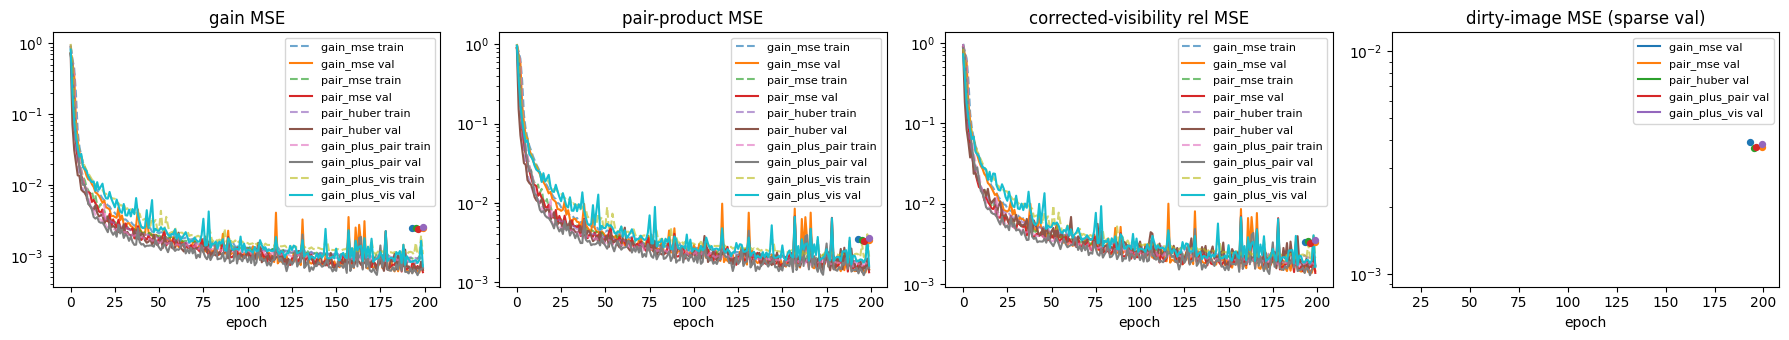

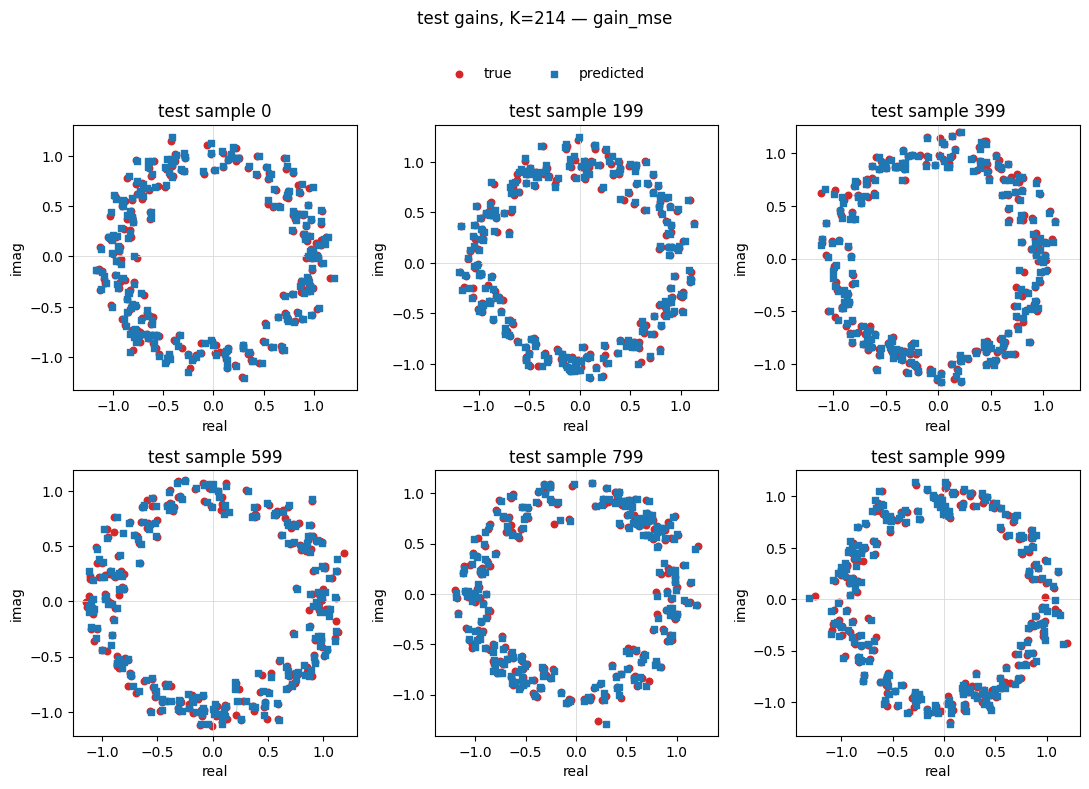

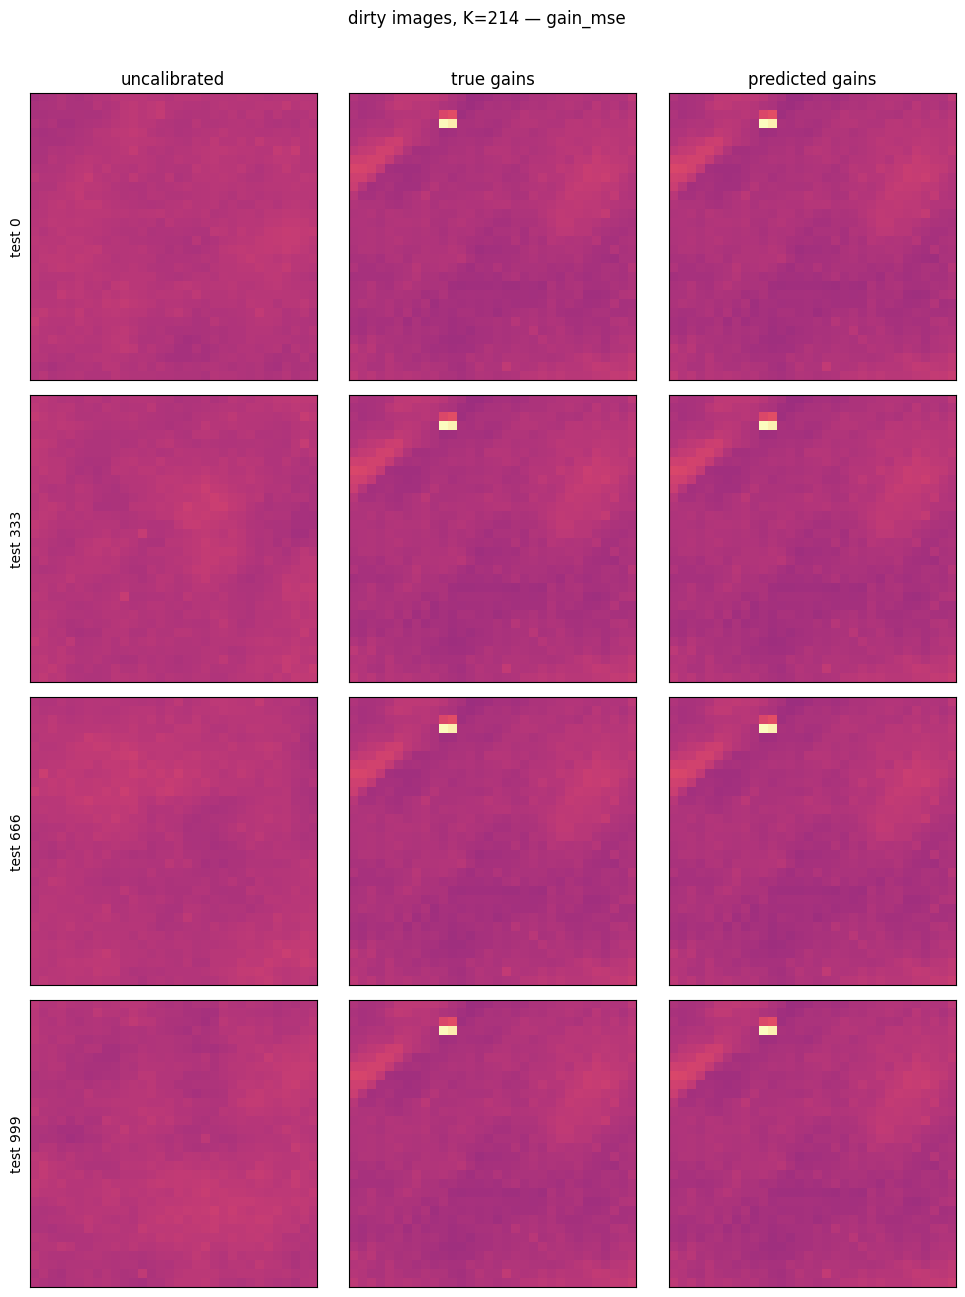

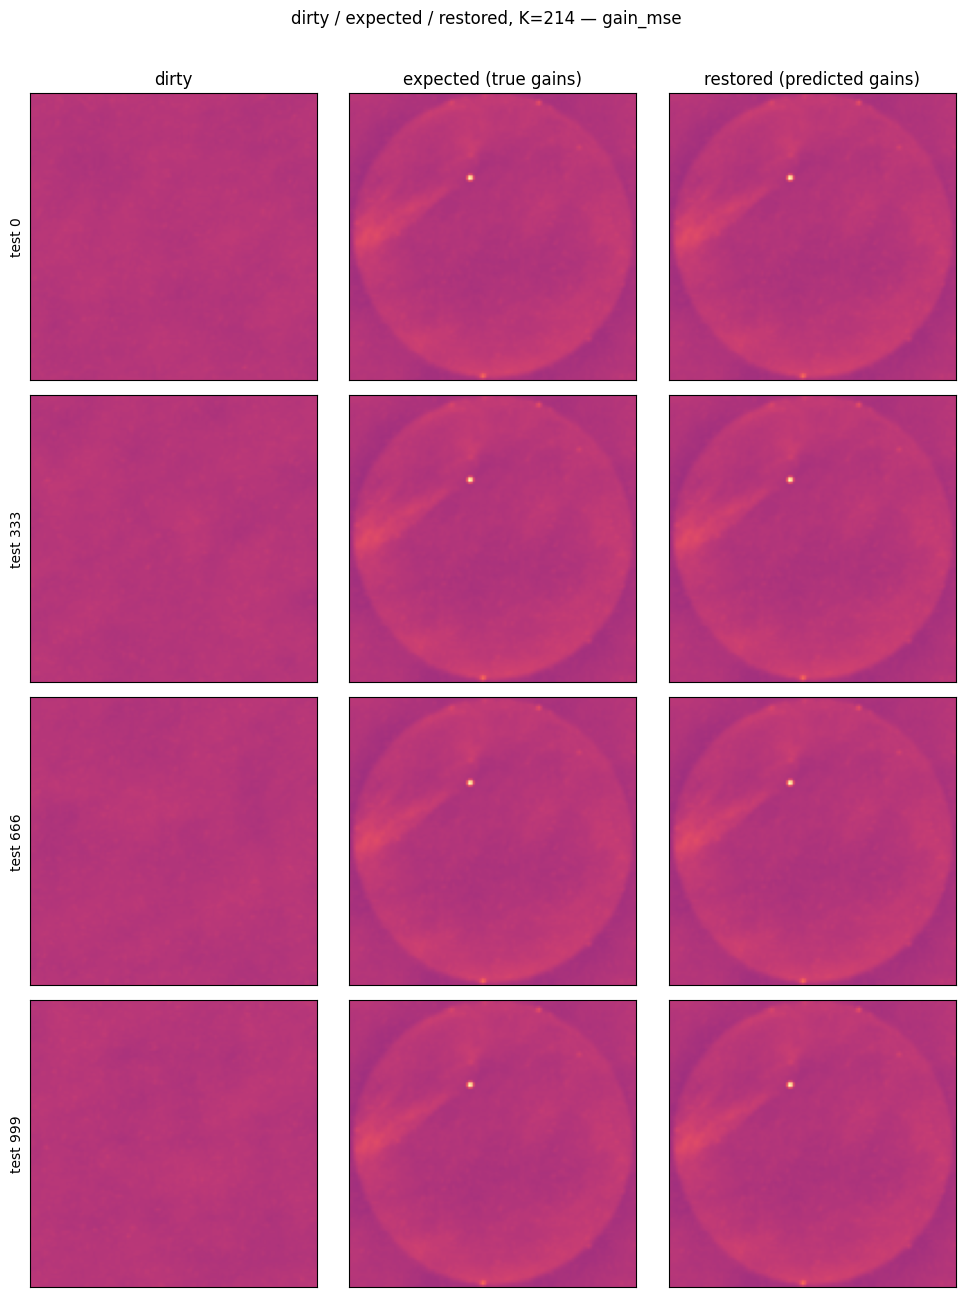

In [ ]:
# Restore loss curves: validation gain, pair, and image; plus original train/val objective.
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for name in RUN_LOSSES:
    for ax,key in zip(axes, ('gain','pair','vis','image')):
        if key != 'image':
            ax.plot([h[key] for h in histories[name]['train']], ls='--', alpha=.65, label=f'{name} train')
        ax.plot([h[key] for h in histories[name]['val']], label=f'{name} val')
        if key in ('gain', 'pair', 'vis', 'image'):
            ax.scatter([best_epochs[name]], [test_results[name][key]], s=18, zorder=4)
for ax,title in zip(axes, ('gain MSE','pair-product MSE','corrected-visibility rel MSE','dirty-image MSE (sparse val)')):
    ax.set_title(title); ax.set_xlabel('epoch'); ax.set_yscale('log'); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR/'loss_comparison_curves.png',dpi=150)
plt.show()

PLOT_LOSS = RUN_LOSSES[0]
PLOT_PREVIOUS_CHECKPOINT = False
PREVIOUS_CHECKPOINT = f'/content/drive/MyDrive/mlp_k{K}.pt'

if PLOT_PREVIOUS_CHECKPOINT:
    plot_model = AntennaMLP(K).to(device)
    plot_model.load_state_dict(torch.load(PREVIOUS_CHECKPOINT, map_location=device, weights_only=True))
    plot_name = 'original saved AntennaMLP'
else:
    plot_model = models[PLOT_LOSS]
    plot_name = PLOT_LOSS

@torch.no_grad()
def collect_test_gains(model):
    model.eval()
    pred_all, true_all = [], []
    for x,y,m in batches('test'):
        gp,gt=to_c(model(mlp_input(x))),to_c(y)
        ph=torch.angle((gp*gt.conj()*m.float()).sum(1,keepdim=True))
        pred_all.append((gp*torch.exp(-1j*ph)).cpu()); true_all.append(gt.cpu())
    return torch.cat(pred_all),torch.cat(true_all)

gp,gt=collect_test_gains(plot_model)
show=torch.linspace(0,len(gp)-1,min(6,len(gp))).long()
fig,axes=plt.subplots(2,3,figsize=(11,7.4))
for ax in axes.ravel(): ax.set_visible(False)
for ax,i in zip(axes.ravel(),show.tolist()):
    ax.set_visible(True)
    t,p=gt[i],gp[i]
    for ant in range(len(t)):
        ax.plot([t[ant].real,p[ant].real],[t[ant].imag,p[ant].imag],color='0.75',lw=.6,zorder=1)
    ax.scatter(t.real,t.imag,s=22,c='#d62728',label='true',zorder=2)
    ax.scatter(p.real,p.imag,s=22,c='#1f77b4',marker='s',label='predicted',zorder=3)
    ax.axhline(0,color='0.85',lw=.6); ax.axvline(0,color='0.85',lw=.6)
    ax.set_aspect('equal',adjustable='datalim'); ax.set_title(f'test sample {i}')
    ax.set_xlabel('real'); ax.set_ylabel('imag')
h,labels=axes[0,0].get_legend_handles_labels()
fig.legend(h[:2],labels[:2],loc='upper center',ncol=2,frameon=False,bbox_to_anchor=(.5,1))
fig.suptitle(f'test gains, K={K} — {plot_name}',y=1.06)
fig.tight_layout(); fig.savefig(OUT_DIR/f'{plot_name.replace(" ","_")}_gains.png',dpi=150,bbox_inches='tight')
plt.show()

@torch.no_grad()
def dirty(x,g,m):
    V=torch.complex(x[:,0],x[:,1]); ok=(m[:,bi] & m[:,bj]).float()
    return make_image(calibrate(V,g)*ok)

plot_model.eval()
show=torch.linspace(0,len(splits['test'])-1,min(4,len(splits['test']))).long()
xb= splits['test'][show]
x,y,m=X[xb].to(device),Y[xb].to(device),M[xb].to(device)
with torch.no_grad():
    true_g=to_c(y); pred_g=to_c(plot_model(mlp_input(x)))
    raw=dirty(x,torch.ones_like(true_g),m).cpu()
    expected=dirty(x,true_g,m).cpu()
    restored=dirty(x,pred_g,m).cpu()

nshow=len(show)
fig,axes=plt.subplots(nshow,3,figsize=(10,3.2*nshow),squeeze=False)
for r in range(nshow):
    row=(raw[r],expected[r],restored[r]); vmax=max(t.abs().max().item() for t in row)+1e-12
    for c,(im,title) in enumerate(zip(row,('uncalibrated','true gains','predicted gains'))):
        ax=axes[r,c]; ax.imshow(im.numpy(),origin='lower',cmap='magma',vmin=-vmax,vmax=vmax)
        if r==0: ax.set_title(title)
        ax.set_xticks([]);ax.set_yticks([])
        if c==0:ax.set_ylabel(f'test {int(show[r])}')
fig.suptitle(f'dirty images, K={K} — {plot_name}',y=1.01)
fig.tight_layout();fig.savefig(OUT_DIR/f'{plot_name.replace(" ","_")}_images.png',dpi=150,bbox_inches='tight')
plt.show()

# Optional: detailed sky, takes awhile.
NPIX = 128
SHOW_SKY = 4

@torch.no_grad()
def high_res_sky(model, n_pix=NPIX, n_show=SHOW_SKY):
    model.eval()
    files=sorted(glob.glob(f'{RAW_DIR}/uncalib_data_*.uvfits'))
    uv=UVData();uv.read(files[0],run_check=False)
    ants=np.union1d(uv.ant_1_array,uv.ant_2_array)
    ii=np.searchsorted(ants,uv.ant_1_array);jj=np.searchsorted(ants,uv.ant_2_array)
    good=(ii<K)&(jj<K)&(ii!=jj)
    ii,jj=ii[good],jj[good]
    lam=299792458.0/float(uv.freq_array.ravel()[0]);uu,vv=(uv.uvw_array[good,:2]/lam).T.astype(np.float64)
    umax=max(np.abs(uu).max(),np.abs(vv).max())+1e-12
    fov=n_pix/(4.0*umax)
    coord=np.linspace(-fov,fov,n_pix);L,Q=np.meshgrid(coord,coord)
    lu,mv=L.ravel(),Q.ravel()

    def cal_vis(V,g,alive,eps=1e-6):
        G=g[:,None]*g.conj()[None,:]
        ok=(alive[:,None]&alive[None,:])&(G.abs()>eps)
        safe_G = torch.where(ok, G, torch.ones_like(G))
        corrected = V * safe_G if CORRECTION_MODE == 'multiply' else V / safe_G
        return torch.where(ok, corrected, torch.zeros_like(V))

    def dft_image(Vmat):
        Vb=Vmat[ii,jj].detach().cpu().numpy().astype(np.complex64)
        img=np.zeros(n_pix*n_pix,np.float32)
        for s in range(0,len(Vb),4096):
            e=min(s+4096,len(Vb))
            ph=np.exp(2j*np.pi*(lu[:,None]*uu[s:e]+mv[:,None]*vv[s:e])).astype(np.complex64)
            img+=(ph*Vb[s:e]).real.sum(1)
        return img.reshape(n_pix,n_pix)/max(len(Vb),1)

    indexes=splits['test'];show=torch.linspace(0,len(indexes)-1,min(n_show,len(indexes))).long()
    x,y,m=X[indexes[show]].to(device),Y[indexes[show]].to(device),M[indexes[show]].to(device)
    V=torch.complex(x[:,0],x[:,1]); gt=to_c(y);gp=to_c(model(mlp_input(x)));one=torch.ones_like(gt)
    images={'dirty':[],'expected':[],'restored':[]}
    for s in range(len(show)):
        alive=m[s].bool()
        for label,gain in [('dirty',one[s]),('expected',gt[s]),('restored',gp[s])]:
            images[label].append(dft_image(cal_vis(V[s],gain,alive)))

    fig,axes=plt.subplots(len(show),3,figsize=(10,3.2*len(show)),squeeze=False)
    for r in range(len(show)):
        row=(images['dirty'][r],images['expected'][r],images['restored'][r]);vmax=max(np.abs(im).max() for im in row)+1e-12
        for c,(im,title) in enumerate(zip(row,('dirty','expected (true gains)','restored (predicted gains)'))):
            ax=axes[r,c];ax.imshow(im,origin='lower',cmap='magma',vmin=-vmax,vmax=vmax)
            if r==0:ax.set_title(title)
            ax.set_xticks([]);ax.set_yticks([])
            if c==0:ax.set_ylabel(f'test {int(show[r])}')
    fig.suptitle(f'dirty / expected / restored, K={K} — {plot_name}',y=1.01)
    fig.tight_layout();fig.savefig(OUT_DIR/f'{plot_name.replace(" ","_")}_sky_128.png',dpi=150,bbox_inches='tight')
    plt.show()

# Uncomment to render high quality sky, slow:
high_res_sky(plot_model)